# **Diplomatura en Ciencia de Datos, Aprendizaje Automático y sus Aplicaciones**

## **Edición 2026**


----

# Trabajo práctico entregable - parte 1

Grupo 5:



*   Bencharski, Constaza
*   Castro, Gerónimo
*   Riego, Daniela
*   Sequeiros, Gerónimo

Fecha:

      14/05/2026

Trabajaremos con la base de datos de `melb_data` presentada a continuación.

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_context('talk')

In [35]:
# Cargamos los datos
melb_data_raw = pd.read_csv(
    'https://cs.famaf.unc.edu.ar/~mteruel/datasets/diplodatos/melb_data.csv')
melb_df = melb_data_raw.copy()
melb_df[:3]

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0


### Información acerca de las variables
Suburb: Suburb

Address: Dirección

Rooms: Número de habitaciones

Price: Precio en dólares australianos

Method:
S - propiedad vendida;
SP - propiedad vendida previamente;
PI - propiedad no vendida (pasó en subasta sin alcanzar el precio de reserva);
PN - vendida previamente no divulgada;
SN - vendida no divulgada;
NB - sin oferta;
VB - oferta del vendedor;
W - retirada antes de la subasta;
SA - vendida después de la subasta;
SS - vendida después de la subasta (precio no divulgado).
N/A - precio o oferta más alta no disponible.

Type:
br - dormitorio(s);
h - casa, cabaña, villa, semi-adosado, terraza;
u - unidad, dúplex;
t - casa adosada;
dev site - sitio de desarrollo;
o res - otra residencia.

SellerG: Agente inmobiliario

Date: Fecha de venta

Distance: Distancia al CBD en kilómetros

Regionname: Región general (Oeste, Noroeste, Norte, Noreste, etc.)

Propertycount: Número de propiedades existentes en el suburbio.

Bedroom2 : Número de dormitorios (obtenido de otra fuente)

Bathroom: Número de baños

Car: Número de plazas de aparcamiento

Landsize: Tamaño del terreno en metros cuadrados

BuildingArea: Superficie construida en metros cuadrados

YearBuilt: Año de construcción de la casa

CouncilArea: Área del consejo municipal

Lattitude: Latitud

Longtitude: Longitud


In [36]:
melb_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

## Ejercicio 1: Encoding

1. Seleccionar todas las filas y columnas del conjunto de datos, **excepto** `BuildingArea` y `YearBuilt`.

2. Decidir si elimina algunas filas o columnas en base al análisis de datos faltantes.

3. Hacer un análisis descriptivo de las variables numéricas del conjunto de datos. Todas tienen el tipo `Dtype` correcto asignado? Armar una matriz (array) sólo con las variables numéricas.  

4. Estudiar las variables categóricas del DataFrame. Aplicar una codificación One-hot encoding a las columnas categóricas que crea pertinente. Si lo consideran necesario, pueden reducir el número de categorías únicas de algunas variables. ¿Cómo trataría la variable `Date`? Armar la matriz de variables categóricas codificada.

5. Concatenar la matriz de variables numéricas a la matriz que codifica las variables categóricas resultante del punto anterior.

Algunas opciones:
  1. Utilizar `OneHotEncoder` junto con el parámetro `categories` para las variables categóricas y luego usar `numpy.hstack` para concatenar el resultado con las variables numéricas.
  2. `DictVectorizer` con algunos pasos de pre-proceso previo.

Recordar también que el atributo `pandas.DataFrame.values` permite acceder a la matriz de numpy subyacente a un DataFrame.


## Desarrollo:

In [37]:
# Punto 1: armamos el dataframe descartando BuildingArea y YearBuilt
melb_df = melb_df.drop(['BuildingArea', 'YearBuilt'], axis=1)
#melb_df.info()

### Parte 2
Hacemos el análisis de datos faltantes en cada columna

In [38]:
# Vamos a ver los tipos de variables que tenemos en cada columna y el tamaño de nuestro dataset
print(melb_df.dtypes)
print('Entradas en el dataset:',melb_df.shape[0])

Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object
Entradas en el dataset: 13580


In [39]:
# Contamos los datos faltantes en las columnas categóricas
cat_col = melb_df.select_dtypes(include='object')
cat_faltantes = (
    cat_col.isna()
    | (cat_col == '')
    | (cat_col == 'NA')
    | (cat_col == 'null')
).sum()

print(cat_faltantes)

Suburb            0
Address           0
Type              0
Method            0
SellerG           0
Date              0
CouncilArea    1369
Regionname        0
dtype: int64


Sólo hay datos faltantes en la columna 'CouncilArea'.

Vemos las variables numéricas:

In [40]:
# Contamos los datos faltantes en las columnas numéricas
num_col = melb_df.select_dtypes(include=['int64', 'float64'])
num_faltantes = num_col.isna().sum()

print(num_faltantes)

Rooms             0
Price             0
Distance          0
Postcode          0
Bedroom2          0
Bathroom          0
Car              62
Landsize          0
Lattitude         0
Longtitude        0
Propertycount     0
dtype: int64


Sólo hay datos faltantes en la variable Car. Pero hay variables numéricas donde pueden ser problemáticos los valores cero

In [41]:
num_ceros = (num_col == 0).sum()
# Ceros en cada variable numérica
print(num_ceros)
# Porcentaje de ceros sobre el total de valores
porcentajes = 100*num_ceros/melb_df.shape[0]
#print(f'Porcentaje de nulos sobre el total de dataset:{porcentajes:.1f}%')
print(f'Porcentaje de nulos sobre el total del dataset: \n{100*num_ceros/melb_df.shape[0]}')

Rooms               0
Price               0
Distance            6
Postcode            0
Bedroom2           16
Bathroom           34
Car              1026
Landsize         1939
Lattitude           0
Longtitude          0
Propertycount       0
dtype: int64
Porcentaje de nulos sobre el total del dataset: 
Rooms             0.000000
Price             0.000000
Distance          0.044183
Postcode          0.000000
Bedroom2          0.117820
Bathroom          0.250368
Car               7.555228
Landsize         14.278351
Lattitude         0.000000
Longtitude        0.000000
Propertycount     0.000000
dtype: float64


Aquí podemos ver que las variables 'Distance', 'Bedroom2', 'Bathroom', 'Car' y 'Landsize' presentan valores nulos.
* La variable 'Distance' está expresada en km, por lo que los valores nulos son aceptables, puede ser el redondeo de unos pocos cientos de metros, y además hay solo 6 valores nulos.
* 'Bedroom2' presenta 16 valores nulos, si bién es raro que una vivienda no cuente con habitaciones podría tratarse de monoambientes. representan una fracción minusucula del total de datos.
* 'Bathroom' presenta 34 valores nulos. si bien es raro encontrar valores nulos aquí, hay una fracción infima de nulos sobre el total. Podría tratarse de propiedades antiguas que efectivamente no cunetan con baño o que no está en condiciones.
* 'Car' cuneta con 1026 entradas nulas. Este ya es un valor significativo sobre el total de la encuesta pero no es raro que una vivienda no cuente con plazas de aparcamiento.
* 'Landsize' presenta 1939 entradas nulas, esto representa un 14% de la encuesta. Acá los valores nulos si son problemáticos porque no puede haber propiedades con tamaño de terreno cero.
En resumen la unica variable que es certeramente problemática es Landsize que cuenta con un 14% de datos faltantes. La variable Car tiene una pequeña cantidad de datos faltantes (0.4%).

### Parte 3
Armamos un dataframe numérico y lo analizamos

In [42]:
# Dataframe numérico
num_df = melb_df.select_dtypes(include=['int64', 'float64']).copy()

print(num_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Rooms          13580 non-null  int64  
 1   Price          13580 non-null  float64
 2   Distance       13580 non-null  float64
 3   Postcode       13580 non-null  float64
 4   Bedroom2       13580 non-null  float64
 5   Bathroom       13580 non-null  float64
 6   Car            13518 non-null  float64
 7   Landsize       13580 non-null  float64
 8   Lattitude      13580 non-null  float64
 9   Longtitude     13580 non-null  float64
 10  Propertycount  13580 non-null  float64
dtypes: float64(10), int64(1)
memory usage: 1.1 MB
None


Hay variables que deberían tomar valores enteros, como 'Postcode', Bedroom2', 'Bathroom' y 'Car'. Tienen valores no enteros?

In [43]:
col_int = ['Rooms', 'Postcode', 'Bedroom2', 'Bathroom', 'Car']
# Vemos si alguna de estas columnas tiene decimales
tiene_decimales = (num_df[col_int].dropna() % 1 != 0).any()
print(tiene_decimales)
print('Esta todo OK')

Rooms       False
Postcode    False
Bedroom2    False
Bathroom    False
Car         False
dtype: bool
Esta todo OK


In [44]:
# Estadística de las variables
print(num_df.describe().T)

                 count          mean            std          min  \
Rooms          13580.0  2.937997e+00       0.955748      1.00000   
Price          13580.0  1.075684e+06  639310.724296  85000.00000   
Distance       13580.0  1.013778e+01       5.868725      0.00000   
Postcode       13580.0  3.105302e+03      90.676964   3000.00000   
Bedroom2       13580.0  2.914728e+00       0.965921      0.00000   
Bathroom       13580.0  1.534242e+00       0.691712      0.00000   
Car            13518.0  1.610075e+00       0.962634      0.00000   
Landsize       13580.0  5.584161e+02    3990.669241      0.00000   
Lattitude      13580.0 -3.780920e+01       0.079260    -38.18255   
Longtitude     13580.0  1.449952e+02       0.103916    144.43181   
Propertycount  13580.0  7.454417e+03    4378.581772    249.00000   

                         25%            50%           75%           max  
Rooms               2.000000       3.000000  3.000000e+00  1.000000e+01  
Price          650000.000000  90300

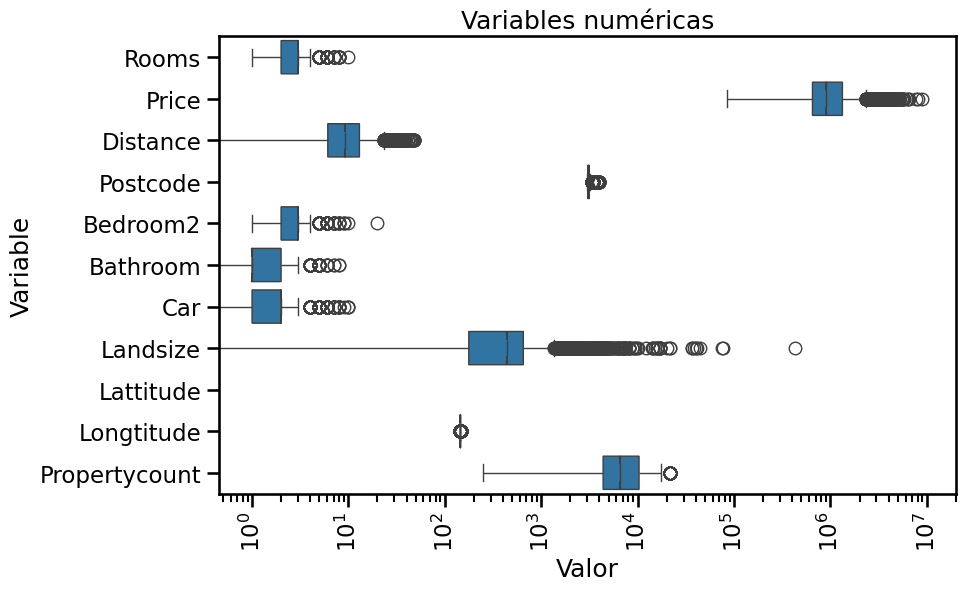

In [45]:
# Figura de boxplot para visualizar los datos

# figura
plt.figure(figsize=(10,6))

sns.boxplot(
    data=num_df.melt(var_name='Variable', value_name='Valor'),
    y='Variable',
    x='Valor',
    notch=True
)

plt.xticks(rotation=90)
plt.title('Variables numéricas')
plt.tight_layout()
plt.xscale('log')

plt.show()

Notamos que la variable **"Landsize"** tiene valoeres iguales a cero. Esto no es posible por lo quie decidimos asignarle valores NaN para imputar más adelante. Decidimos to ar como umbral para el tamaño de propiedad mínimo de $20~m^2$

In [46]:
num_df.loc[num_df['Landsize'] < 20, 'Landsize'] = np.nan
print(num_df.Landsize.info())

<class 'pandas.core.series.Series'>
RangeIndex: 13580 entries, 0 to 13579
Series name: Landsize
Non-Null Count  Dtype  
--------------  -----  
11630 non-null  float64
dtypes: float64(1)
memory usage: 106.2 KB
None


Vamos a ver la matriz de correlación de datos numéricos para ver si hay alguna variable redundante

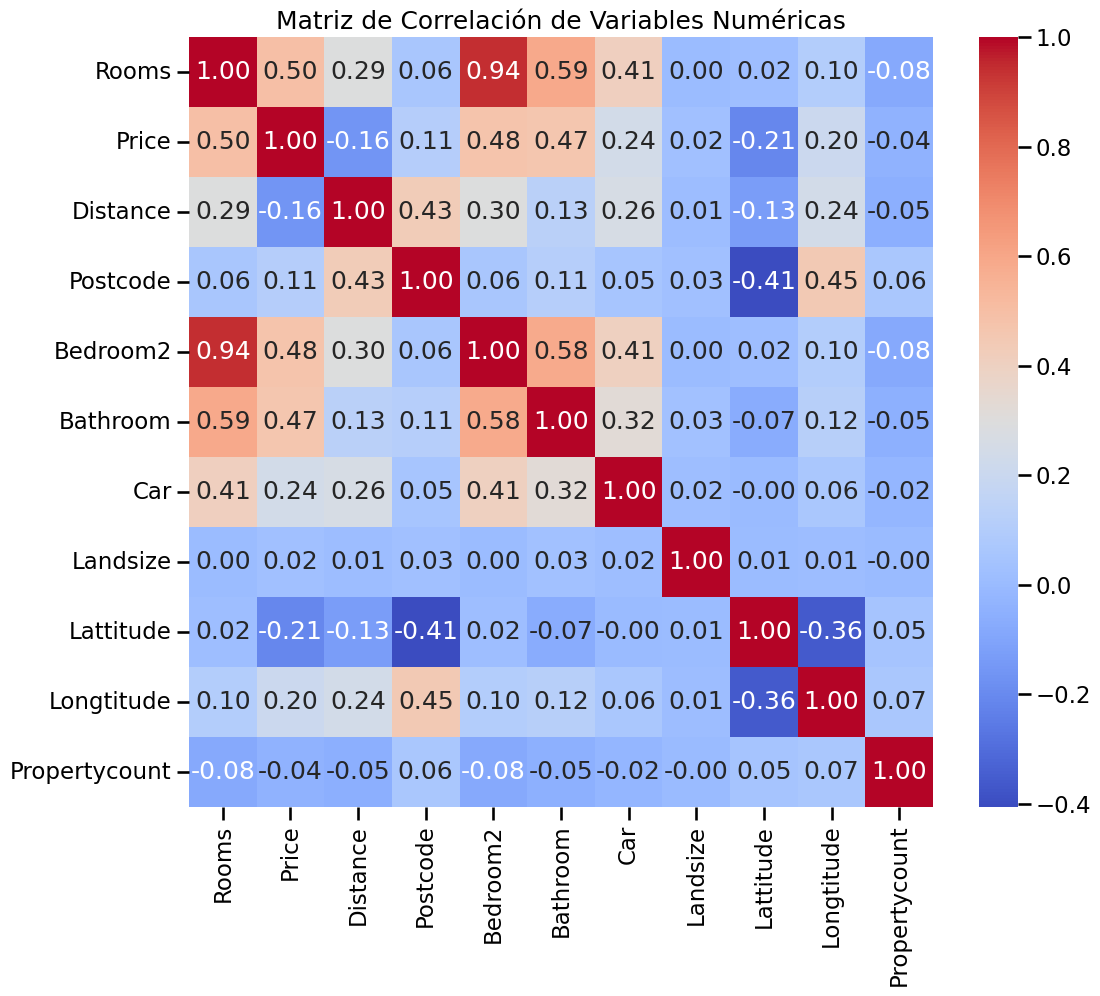

In [47]:
# Matriz de correlación
plt.figure(figsize=(12, 10))
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

Acá observamos que lacorrelación entre la variable **Rooms** y **Bedroom2** es del 95%. Como son redundantes decidimos descartar Bedroom2 para el análisis, ya que es de una fuente alternativa a la del dataset.

In [48]:
Bedroom2 = num_df.Bedroom2
Rooms = num_df.Rooms
pd.crosstab(Rooms,Bedroom2)

Bedroom2,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,20.0
Rooms,,,,,,,,,,,,
1,0,663,16,2,0,0,0,0,0,0,0,0
2,5,21,3539,74,8,1,0,0,0,0,0,0
3,8,5,162,5626,73,5,0,0,0,1,0,1
4,3,2,19,175,2473,15,0,0,0,1,0,0
5,0,0,1,18,42,531,2,1,1,0,0,0
6,0,0,0,1,4,2,59,1,0,0,0,0
7,0,0,0,0,0,2,0,8,0,0,0,0
8,0,0,0,0,1,0,2,0,4,1,0,0
10,0,0,0,0,0,0,0,0,0,0,1,0


En la tabla de contingencia entre las variables "Rooms" y "Bedroom2" se observan algunos casos inconsistentes, por ejemplo viviendas con una cantidad de habitaciones (Rooms) mayor que cero, pero con Bedroom2 = 0. Dado que una vivienda con habitaciones difícilmente no posea ningún dormitorio, estos casos sugieren posibles errores o inconsistencias en la variable Bedroom2.

Además, la distribución muestra una correspondencia mucho más coherente entre ambas variables cuando se considera Rooms, ya que la mayoría de los registros siguen la relación esperada entre cantidad total de habitaciones y dormitorios. Por este motivo, se decidió conservar la variable "Rooms", considerando que presenta datos más confiables y consistentes.

In [49]:
num_df = num_df.drop(['Bedroom2'], axis=1)
#num_df.info()

De la misma forma, analizaremos la variable **"Bathroom"** con respecto a la variable "Rooms"

In [31]:
Bathroom = num_df.Bathroom
pd.crosstab(Bathroom,Rooms)

Rooms,1,2,3,4,5,6,7,8,10
Bathroom,,,,,,,,,
0.0,1,19,11,3,0,0,0,0,0
1.0,674,3117,3250,452,17,2,0,0,0
2.0,6,504,2459,1720,260,20,3,2,0
3.0,0,8,153,469,244,35,5,2,1
4.0,0,0,5,41,47,9,2,2,0
5.0,0,0,1,2,25,0,0,0,0
6.0,0,0,2,0,2,1,0,0,0
7.0,0,0,0,0,1,0,0,1,0
8.0,0,0,0,1,0,0,0,1,0


En esta tabla notamos que hay propiedades que, si bien tienen mas de una habitación, no tienen baños, lo cual es poco probable. Vemos que hay un total de 34 casos en los que esto ocurre. Suponemos entonces que se trata de un error al ingresar los datos de la propiedad.

Para corregirlo consideramos que las propiedades que tengan más de una habitación y no listen baños, serán considerados datos faltantes.

In [66]:
num_df.loc[num_df.Bathroom==0,'Bathroom']=np.nan

cols2 = num_df[num_df == 0].count(axis=0)#/len(melb_df.index)
cols2[cols2 > 0]

,0
Distance,6
Car,1026


In [67]:
num_df['Bathroom'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 13580 entries, 0 to 13579
Series name: Bathroom
Non-Null Count  Dtype  
--------------  -----  
13546 non-null  float64
dtypes: float64(1)
memory usage: 106.2 KB


Analizamos la variable **Distance:**

Observamos que hay solo 6 valores nulos y dado que la variable representa la distancia al centro de la ciudad es totalmente posible que existan propiedades posicionadas en dicho sector. Lo que podemos estudiar, para convencernos que son valores reales y no faltantes, es el precio de dichas propiedades y el tipo de propiedad dado que al estar en la zona centrica deberían tener en general precios más elevados, estar en el mismo suburbio y tratatarse de unidades tipo apartamentos.

In [68]:
melb_df.loc[melb_df["Distance"] == 0, ["Price", "Type","Rooms","Suburb"]]

,Price,Type,Rooms,Suburb
9620,740000.0,u,2,Melbourne
10393,720000.0,u,2,Melbourne
10739,1075000.0,u,2,Melbourne
11428,387000.0,u,2,Melbourne
12073,565000.0,u,2,Melbourne
12074,540000.0,u,2,Melbourne


Observamos que los seis casos pertenecen al mismo suburbio y corresponden al mismo tipo de propiedad (apartamentos), lo cual resulta consistente y esperable. En cuanto al precio, no es posible extraer conclusiones claras debido a la alta variabilidad observada entre esos casos. Esto puede explicarse porque el precio depende de múltiples factores adicionales, como el tamaño de la propiedad, el año de construcción, el estado de conservación, entre otros. Por lo tanto consideramos que son valores que si representan a la variable y no datos faltantes.

Analizaremos la variable **"Car"**

Vimos que hay unos 1026 valores igual a 0 en dicha variable. Para decidir si corresponden a propiedades que no tienen cochera, en primer lugar miramos que tipo de propiedades son.

In [69]:
melb_df.loc[melb_df["Car"] == 0, ["Type"]].value_counts()

,count
Type,
h,846
u,165
t,15


No sabemos como analizar la veracidad de los valores nulos para la cantidad de plazas de aparcamiento. Vemos que la mayor parte corresponde a propiedades tipo h, y resulta raro pensar en casas sin cochera, pero ausumimos que son casos posibles. Entonces, decidimos no tratarlos como valores faltantes.

La variable **'Lattitude'** no se visualiza en esta escala porque es negativa.
Algunas variables relacionadas pueden ser visualizadas mejor agrupadas en otros gráficos


/tmp/ipykernel_12157/1151269389.py:21: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


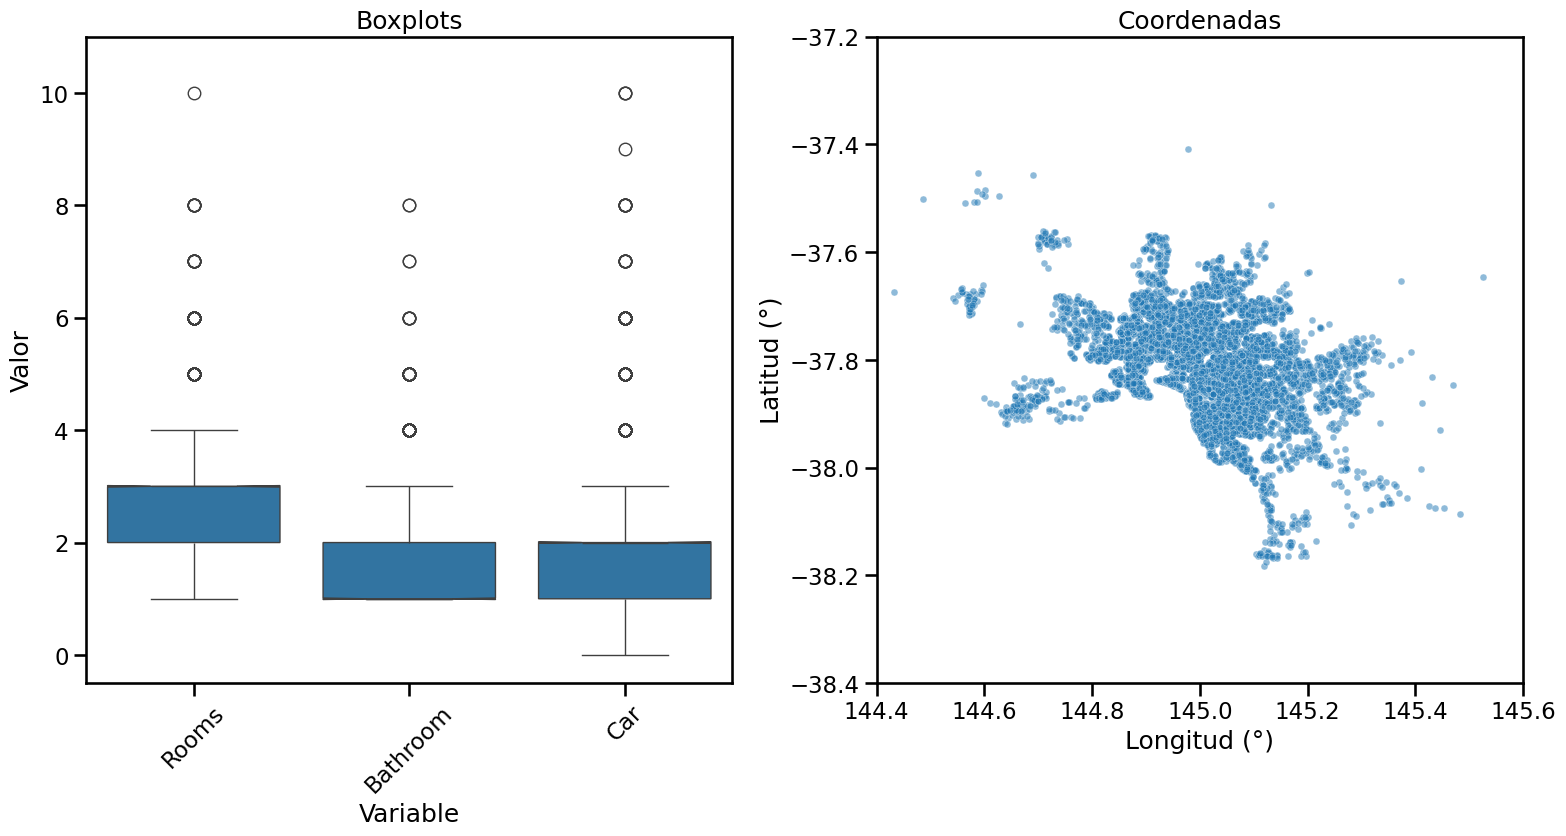

In [70]:
col_histograma = ['Rooms', 'Bathroom', 'Car']
# Figura de 2 paneles

fig, axes = plt.subplots(1, 2, figsize=(16,10))

# PANEL 1 — Boxplot de 4 variables
sns.boxplot(
    data=num_df[col_histograma].melt(var_name='Variable', value_name='Valor'),
    x='Variable',
    y='Valor',
    notch=True,
    ax=axes[0])
axes[0].set_ylim(-0.5, 11)
axes[0].set_title('Boxplots')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_box_aspect(1)

# PANEL 2 — Scatter


sns.scatterplot(
    data=num_df,
    x='Longtitude',
    y='Lattitude',
    palette='tab10',
    s=25,
    alpha = 0.5,
    ax=axes[1]
)
axes[1].set_xlim(144.4, 145.6)
axes[1].set_ylim(-38.4, -37.2)
axes[1].set_xlabel('Longitud (°)')
axes[1].set_ylabel('Latitud (°)')
axes[1].set_title('Coordenadas')
axes[1].set_box_aspect(1)
plt.tight_layout()
plt.show()

En el primer panel se observa un solapamiento entre la mediana (Q2) y el tercer cuartil (Q3) en todos los casos. Esto se debe a la alta frecuencia de ciertos valores discretos —3 en Rooms, 1 en Bathroom y 2 en Car— que concentran gran parte de las observaciones y provocan que ambos cuartiles coincidan.
El segundo panel muestra la distribución geográfica de las propiedades. No aparenta tener outliers.

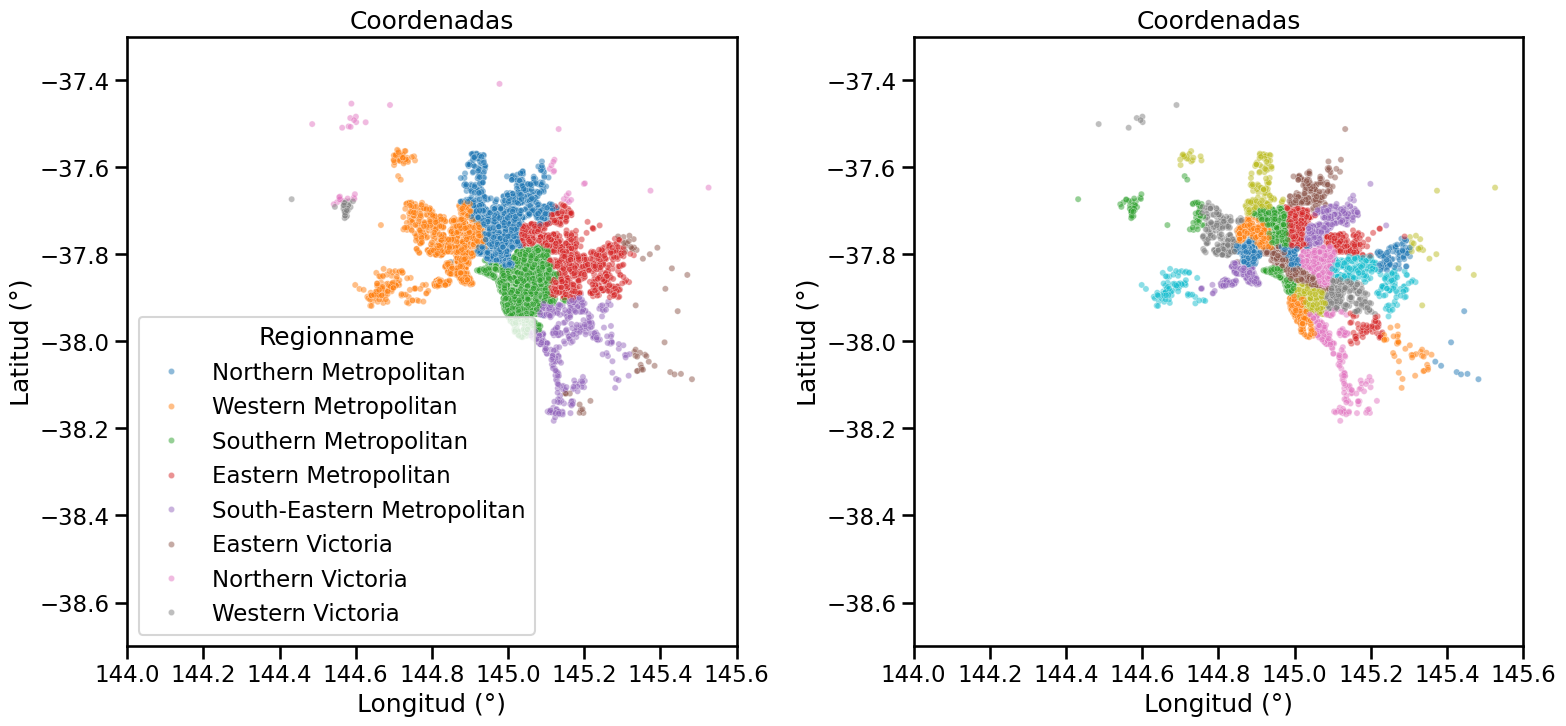

In [71]:
# Figura de 2 paneles

fig, axes = plt.subplots(1, 2, figsize=(16,10))

# PANEL 1 — Scatter Region
sns.scatterplot(
    data=num_df,
    x='Longtitude',
    y='Lattitude',
    hue = melb_df['Regionname'],
    palette='tab10',
    s=20,
    alpha = 0.5,
    ax=axes[0]
)
axes[0].set_xlim(144, 145.6)
axes[0].set_ylim(-38.7, -37.3)
axes[0].set_xlabel('Longitud (°)')
axes[0].set_ylabel('Latitud (°)')
axes[0].set_title('Coordenadas')
axes[0].set_box_aspect(1)


# PANEL 2 — Scatter CounsilArea
sns.scatterplot(
    data=num_df,
    x='Longtitude',
    y='Lattitude',
    hue = melb_df['CouncilArea'],
    palette='tab10',
    legend=False,
    s=20,
    alpha = 0.5,
    ax=axes[1]
)
axes[1].set_xlim(144, 145.6)
axes[1].set_ylim(-38.7, -37.3)
axes[1].set_xlabel('Longitud (°)')
axes[1].set_ylabel('Latitud (°)')
axes[1].set_title('Coordenadas')
axes[1].set_box_aspect(1)
plt.tight_layout()
plt.show()

a partir de la observación de variables categóricas como Regionname y CouncilArea en función de las cordenadas, podemos ver que las categorías definen regiones geográficas claras.

In [72]:
# Convertimos el dataframe numerico a un array de numpy
num_array = num_df.to_numpy()

In [73]:
num_df['Landsize'].isna().sum()
num_df['Car'].isna().sum()

np.int64(62)

Luego de trabajar sobre cada variable, reanalizamos los datos faltantes del tipo numérico antes de hacer el encoding e imputar ya que en este proceso se han agregado datos faltantes a las variables "Bathroom" y "Landsize".


In [74]:
df_num_faltantes = num_df.isna().sum()
print(df_num_faltantes)

Rooms               0
Price               0
Distance            0
Postcode            0
Bathroom           34
Car                62
Landsize         1950
Lattitude           0
Longtitude          0
Propertycount       0
dtype: int64


La imputacion de variables es diferente para variables categoricas y numericas, por lo cual es importante distinguir los casos.

In [77]:
cat_df = melb_df.select_dtypes(include=['object']).copy()

print(cat_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Suburb       13580 non-null  object
 1   Address      13580 non-null  object
 2   Type         13580 non-null  object
 3   Method       13580 non-null  object
 4   SellerG      13580 non-null  object
 5   Date         13580 non-null  object
 6   CouncilArea  12211 non-null  object
 7   Regionname   13580 non-null  object
dtypes: object(8)
memory usage: 848.9+ KB
None


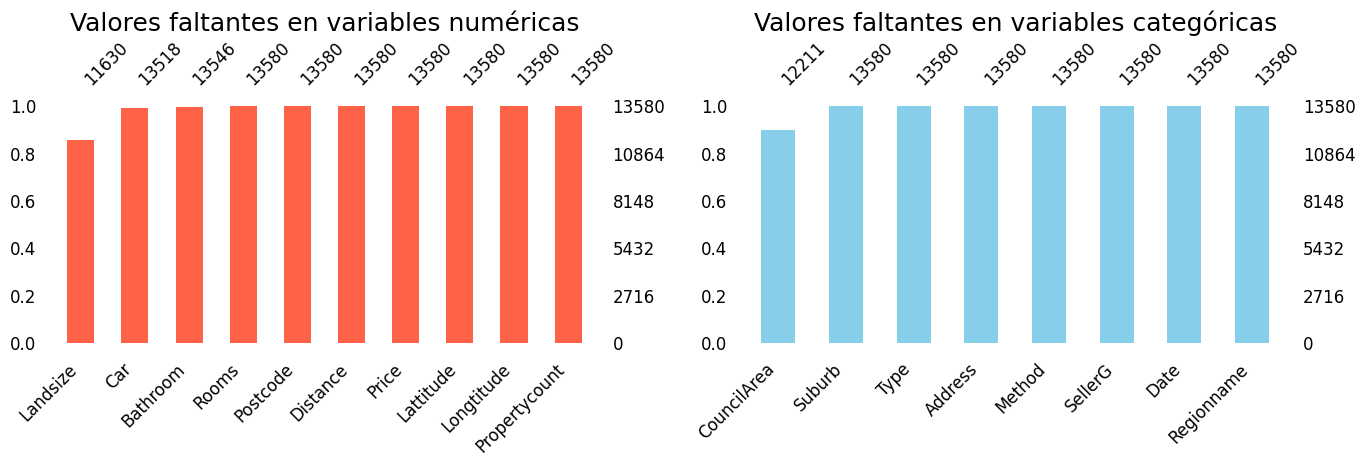

In [79]:
import matplotlib.pyplot as plt
import missingno as msno

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

msno.bar(num_df, figsize=(6, 4), sort="ascending", fontsize=12, color='tomato', ax=axes[0])
axes[0].set_title('Valores faltantes en variables numéricas')

msno.bar(cat_df, figsize=(6, 4), sort="ascending", fontsize=12, color='skyblue', ax=axes[1])
axes[1].set_title('Valores faltantes en variables categóricas')

plt.tight_layout()
plt.show()

Variables numéricas: La variable con más valores faltantes es "landsize", seguido por "Car" y "Bathroom".

Variables categóricas: La única variable con datos faltantes es "CouncilArea"


Ahora queremos ver si existe alguna correlación entre las variables numéricas con datos faltantes.

<Axes: >

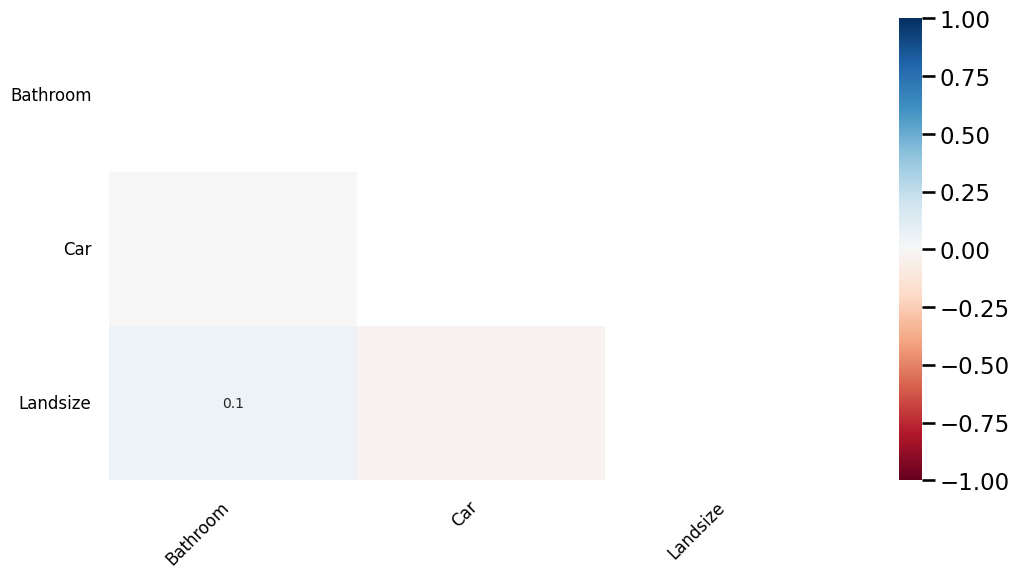

In [83]:
msno.heatmap(num_df, figsize=(12, 6), fontsize=12)

Claramente no hay correlación entre datos faltantes.

### Parte 4
Estudiar las variables categóricas del DataFrame. Aplicar una codificación One-hot encoding a las columnas categóricas que crea pertinente. Si lo consideran necesario, pueden reducir el número de categorías únicas de algunas variables. ¿Cómo trataría la variable `Date`? Armar la matriz de variables categóricas codificada.

Ya vimos que la única categoria con datos faltantes es 'CouncilArea'.

In [84]:
print('Cantidad de categorías en cada columna: \n', cat_df.nunique().sort_values())

Cantidad de categorías en cada columna: 
 Type               3
Method             5
Regionname         8
CouncilArea       33
Date              58
SellerG          268
Suburb           314
Address        13378
dtype: int64



Nuestra estrategia consiste en conservar únicamente las variables potencialmente relacionadas con los datos a imputar. En particular, se consideró que las variables 'Type' y 'Regionname' podrían aportar información relevante debido a su relación con las características de la columna con datos a imputar 'CouncilArea', 'Car' y 'Landsize'. Por ello, descartamos las otras columnas para el análisis, teniendo en cuenta que su alta cardinalidad consumiría recursos computacionales elevados, por lo que se decidió priorizar las categorías más reducidas.

In [85]:
cat_df.drop(['Method', 'SellerG', 'Suburb', 'Address'], axis=1, inplace=True)

Por otro lado la variable 'Date' es ordinal, pero no es facil de interpretar si se traduce directamente en un número. Se puede traducir en tres variables numéricas: día, mes, año

In [86]:
from datetime import date


date_temp = pd.to_datetime(cat_df['Date'], format='%d/%m/%Y')


date_df = pd.DataFrame({
    'Day': date_temp.dt.day,
    'Month': date_temp.dt.month,
    'Year': date_temp.dt.year
})

print(date_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Day     13580 non-null  int32
 1   Month   13580 non-null  int32
 2   Year    13580 non-null  int32
dtypes: int32(3)
memory usage: 159.3 KB
None


In [87]:
cat_df.drop(['Date'], axis=1, inplace=True)

In [88]:
cat_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Type         13580 non-null  object
 1   CouncilArea  12211 non-null  object
 2   Regionname   13580 non-null  object
dtypes: object(3)
memory usage: 318.4+ KB


In [89]:
from sklearn.preprocessing import OneHotEncoder

#inicializamos el encoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded_categorical_data = encoder.fit_transform(cat_df)

print(f"{encoded_categorical_data.shape}")

(13580, 45)


In [90]:
#Convertimos a un DataFrame de Pandas
encoded_categorical_data = pd.DataFrame(encoded_categorical_data, columns=encoder.get_feature_names_out())

print(encoded_categorical_data.info())
display(encoded_categorical_data.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 45 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Type_h                                 13580 non-null  float64
 1   Type_t                                 13580 non-null  float64
 2   Type_u                                 13580 non-null  float64
 3   CouncilArea_Banyule                    13580 non-null  float64
 4   CouncilArea_Bayside                    13580 non-null  float64
 5   CouncilArea_Boroondara                 13580 non-null  float64
 6   CouncilArea_Brimbank                   13580 non-null  float64
 7   CouncilArea_Cardinia                   13580 non-null  float64
 8   CouncilArea_Casey                      13580 non-null  float64
 9   CouncilArea_Darebin                    13580 non-null  float64
 10  CouncilArea_Frankston                  13580 non-null  float64
 11  Co

,Type_h,Type_t,Type_u,CouncilArea_Banyule,CouncilArea_Bayside,CouncilArea_Boroondara,CouncilArea_Brimbank,CouncilArea_Cardinia,CouncilArea_Casey,CouncilArea_Darebin,...,CouncilArea_Yarra Ranges,CouncilArea_nan,Regionname_Eastern Metropolitan,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


La siguiente celda contiene otra manera de hacer OneHotEncoding, la cual fue descartada porque no guardaba registro de los valores NaN.

In [ ]:

#type_dummies    = pd.get_dummies(cat_df['Type'], prefix='Type', drop_first = False)
#method_dummies  = pd.get_dummies(cat_df['Method'], prefix='Method', drop_first = False)
#region_dummies  = pd.get_dummies(cat_df['Regionname'], prefix='Region', drop_first = False)
#council_dummies = pd.get_dummies(cat_df['CouncilArea'], prefix='Council', drop_first = False)
#cat_df_encoded  = pd.concat([cat_df,
#                            type_dummies,
#                            method_dummies,
#                            region_dummies]#,                            council_dummies]
#                            , axis=1)

#cat_df_encoded.drop(['Type', 'Method', 'Regionname', 'CouncilArea'], axis=1, inplace=True)
# además, descaramos las variables qu eno codificamos porque no aportan información relevante (JUSTIFICAR)
#c#at_df_encoded.drop(['Suburb', 'Address', 'SellerG'], axis=1, inplace=True)
#print(cat_df_encoded.info())
#cat_df_encoded.drop(['Type', 'Method', 'Regionname'], axis=1, inplace=True)
#print(cat_df_encoded.info())

### Parte 5
Concatenar la matriz de variables numéricas a la matriz que codifica las variables categóricas resultante del punto anterior.

In [91]:
# Creamos primero el df entero con el encoding
melb_df_encoded = pd.concat([num_df, encoded_categorical_data], axis=1)
print(melb_df_encoded.info())

# Cuantos datos faltantes hay
num_faltantes2 = melb_df_encoded.isna().sum()

print(num_faltantes2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 55 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rooms                                  13580 non-null  int64  
 1   Price                                  13580 non-null  float64
 2   Distance                               13580 non-null  float64
 3   Postcode                               13580 non-null  float64
 4   Bathroom                               13546 non-null  float64
 5   Car                                    13518 non-null  float64
 6   Landsize                               11630 non-null  float64
 7   Lattitude                              13580 non-null  float64
 8   Longtitude                             13580 non-null  float64
 9   Propertycount                          13580 non-null  float64
 10  Type_h                                 13580 non-null  float64
 11  Ty

In [92]:

# Creamos una matriz de np con las variables numéricas
melb_encoded = melb_df_encoded.select_dtypes(include=['int64', 'float64', 'bool']).to_numpy()
print('Tamaño de la matriz:',melb_encoded.shape)
print('\n Vemos una muestra de la matriz:')
print(melb_encoded[:5,:60])

Tamaño de la matriz: (13580, 55)

 Vemos una muestra de la matriz:
[[ 2.000000e+00  1.480000e+06  2.500000e+00  3.067000e+03  1.000000e+00
   1.000000e+00  2.020000e+02 -3.779960e+01  1.449984e+02  4.019000e+03
   1.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  1.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  1.000000e+00
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00]
 [ 2.000000e+00  1.035000e+06  2.500000e+00  3.067000e+03  1.000000e+00
   0.000000e+00  1.560000e+02 -3.780790e+01  1.449934e+02  4.019000e

## Ejercicio 2: Imputación por KNN

En el teórico se presentó el método `IterativeImputer`, entre otros, para imputar valores faltantes en variables numéricas. Sin embargo, los ejemplos presentados sólo utilizaban algunas variables numéricas presentes en el conjunto de datos. En este ejercicio, utilizaremos la matriz de datos codificada para imputar datos faltantes de manera más precisa.

1. Agregue a la matriz obtenida en el punto anterior las columnas `YearBuilt` y `BuildingArea`.
2. Aplique una instancia de `IterativeImputer` con un estimador `KNeighborsRegressor` para imputar los valores de las variables. ¿Es necesario estandarizar o escalar los datos previamente?
3. Realice un gráfico mostrando la distribución de cada variable antes de ser imputada, y con ambos métodos de imputación.

In [93]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.impute import IterativeImputer

## Desarrollo

In [94]:
# Primero recuperamos las variables 'YearBuilt' y 'BuildingArea'
melb_df_encoded = pd.concat([melb_df_encoded, melb_data_raw[['YearBuilt', 'BuildingArea']]], axis=1)
#print(melb_df_encoded.info())

Analizamos las variables "YearBuilt' y 'BuildingArea' con la intención de remover posibles valores atípicos o erróneos.

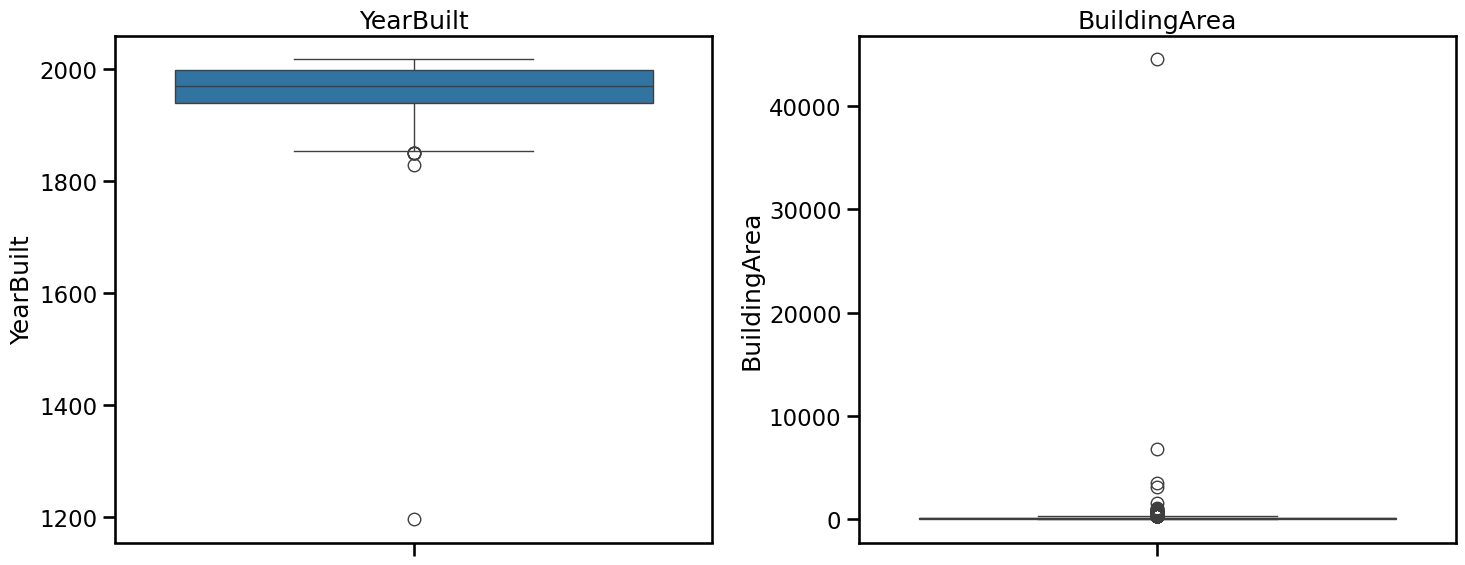

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Boxplot YearBuilt
sns.boxplot(
    data=melb_df_encoded,
    y='YearBuilt',
    ax=axes[0]
)

axes[0].set_title('YearBuilt')

# Boxplot BuildingArea
sns.boxplot(
    data=melb_df_encoded,
    y='BuildingArea',
    ax=axes[1]
)

axes[1].set_title('BuildingArea')
#axes[1].set_yscale('log')


plt.tight_layout()
plt.show()

**Yearbuilt**: como Melbourn se fundó en  1839, tomaremos ese valor como cota inferior y como cota superior el año de la encuesta 2018. Asignaremos NaNs a los valores fuera de este rango para luego imputarlos.

**BuildingArea**: Teniendo en cuenta que esta categoría representa los metros cuadrados cubiertos, decidimos poner como cota inferior $8~m^{2}$. Y como cota superior tomaremos los valores que representan el 95% de los datos.

In [96]:
melb_df_encoded.loc[melb_df_encoded['YearBuilt'] < 1839, 'YearBuilt'] = np.nan
melb_df_encoded.loc[melb_df_encoded['BuildingArea'] < 8, 'BuildingArea'] = np.nan
melb_df_encoded.loc[melb_df_encoded['BuildingArea'] > melb_df_encoded['BuildingArea'].quantile(0.95), 'BuildingArea'] = np.nan

In [97]:
# Convertimos todos los datos al tipo flotante
melb_df_encoded = melb_df_encoded.astype('float64')

In [98]:
print(melb_df_encoded.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 57 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rooms                                  13580 non-null  float64
 1   Price                                  13580 non-null  float64
 2   Distance                               13580 non-null  float64
 3   Postcode                               13580 non-null  float64
 4   Bathroom                               13546 non-null  float64
 5   Car                                    13518 non-null  float64
 6   Landsize                               11630 non-null  float64
 7   Lattitude                              13580 non-null  float64
 8   Longtitude                             13580 non-null  float64
 9   Propertycount                          13580 non-null  float64
 10  Type_h                                 13580 non-null  float64
 11  Ty

Antes de realizar la imputación por KNN, así como el análisis de componentes principales, estandarizamos los datos, esto es importante porque ambos algoritmos son matemáticamente dependientes de la magnitud y escala de los datos.

Al estandarizar, ponemos todas las variables en igualdad de escalas, lo que garantiza que:



*   En KNN (basado en norma): Las variables con números más grandes no dominen injustamente el cálculo de la norma entre los puntos a la hora de buscar los "vecinos más cercanos".
*   En PCA (basado en varianza): Las variables con magnitudes mayores no sesguen artificialmente la dirección de los componentes principales, permitiendo que el algoritmo capture la verdadera estructura matemática de los datos sin importar sus unidades de medida originales.




In [99]:
# Estandarizamos los datos
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
print(scaler.fit(melb_df_encoded))
melb_encoded_scaled = scaler.fit_transform(melb_df_encoded) # notar que melb_encoded_scaled es un array de numpy no un dataframe


StandardScaler()


In [100]:
knn_estimator = KNeighborsRegressor(n_neighbors=5, )
imputer = IterativeImputer(estimator=knn_estimator, max_iter=20, random_state=42)
melb_encoded_imputed = imputer.fit_transform(melb_encoded_scaled)



/usr/local/lib/python3.12/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [101]:
print(melb_encoded_imputed.shape)


(13580, 57)


Ahora vamos a desestandarizar los datos para poder comparar distribuciones antes de la imputación y luego de la imputación.

Esto lo hacemos porque queremos responder preguntas como:

¿los valores imputados tienen sentido físico?
¿la distribución original se deformó?
¿aparecieron valores raros?
¿se desplazó la media real?

Y eso es muchísimo más fácil en las unidades originales.

In [102]:
melb_imputed = scaler.inverse_transform(melb_encoded_imputed)

In [103]:
melb_imputed_df = pd.DataFrame(melb_imputed, columns=melb_df_encoded.columns)
print(melb_imputed_df.info())

display(melb_imputed_df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 57 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rooms                                  13580 non-null  float64
 1   Price                                  13580 non-null  float64
 2   Distance                               13580 non-null  float64
 3   Postcode                               13580 non-null  float64
 4   Bathroom                               13580 non-null  float64
 5   Car                                    13580 non-null  float64
 6   Landsize                               13580 non-null  float64
 7   Lattitude                              13580 non-null  float64
 8   Longtitude                             13580 non-null  float64
 9   Propertycount                          13580 non-null  float64
 10  Type_h                                 13580 non-null  float64
 11  Ty

,Rooms,Price,Distance,Postcode,Bathroom,Car,Landsize,Lattitude,Longtitude,Propertycount,...,Regionname_Eastern Metropolitan,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria,YearBuilt,BuildingArea
0,2.0,1480000.0,2.5,3067.0,1.0,1.0,202.0,-37.7996,144.9984,4019.0,...,-1.387779e-17,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1914.0,96.4
1,2.0,1035000.0,2.5,3067.0,1.0,0.0,156.0,-37.8079,144.9934,4019.0,...,-1.387779e-17,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1900.0,79.0
2,3.0,1465000.0,2.5,3067.0,2.0,0.0,134.0,-37.8093,144.9944,4019.0,...,-1.387779e-17,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1900.0,150.0
3,3.0,850000.0,2.5,3067.0,2.0,1.0,94.0,-37.7969,144.9969,4019.0,...,-1.387779e-17,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1932.4,125.0
4,4.0,1600000.0,2.5,3067.0,1.0,2.0,120.0,-37.8072,144.9941,4019.0,...,-1.387779e-17,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2014.0,142.0


In [105]:
melb_encoded_imputed_df = pd.DataFrame(melb_encoded_imputed, columns=melb_df_encoded.columns) #Se usa el dataframe con los datos estandarizados
print(melb_encoded_imputed_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 57 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rooms                                  13580 non-null  float64
 1   Price                                  13580 non-null  float64
 2   Distance                               13580 non-null  float64
 3   Postcode                               13580 non-null  float64
 4   Bathroom                               13580 non-null  float64
 5   Car                                    13580 non-null  float64
 6   Landsize                               13580 non-null  float64
 7   Lattitude                              13580 non-null  float64
 8   Longtitude                             13580 non-null  float64
 9   Propertycount                          13580 non-null  float64
 10  Type_h                                 13580 non-null  float64
 11  Ty

In [109]:
melb_encoded_imputed_df['CouncilArea_nan'].value_counts()

,count
CouncilArea_nan,
-0.334831,12211
2.986578,1369


Se observa que ahora nuestro DataFrame no tiene valores faltantes.

Luego de aplicar dos métodos distintos de One-Hot Encoding, se concluyó que no es posible imputar por el método iterativo de KNNRegressor la variable categórica "CouncilArea". El principal inconveniente radica en la imposibilidad de preservar los valores faltantes (NaN) tras el proceso de codificación.

Al realizar el encoding, las filas que originalmente contenían valores faltantes reciben ceros en todas las columnas generadas. En consecuencia, durante la etapa de imputación, esos valores no son reconocidos como faltantes, ya que las celdas contienen datos numéricos válidos. Como alternativa, puede añadirse una columna indicadora de las filas que originalmente poseían valores nulos; sin embargo, esto no resuelve el problema de la imputación de dichos valores.


Las columnas numéricas fueron exitosamente imputadas.

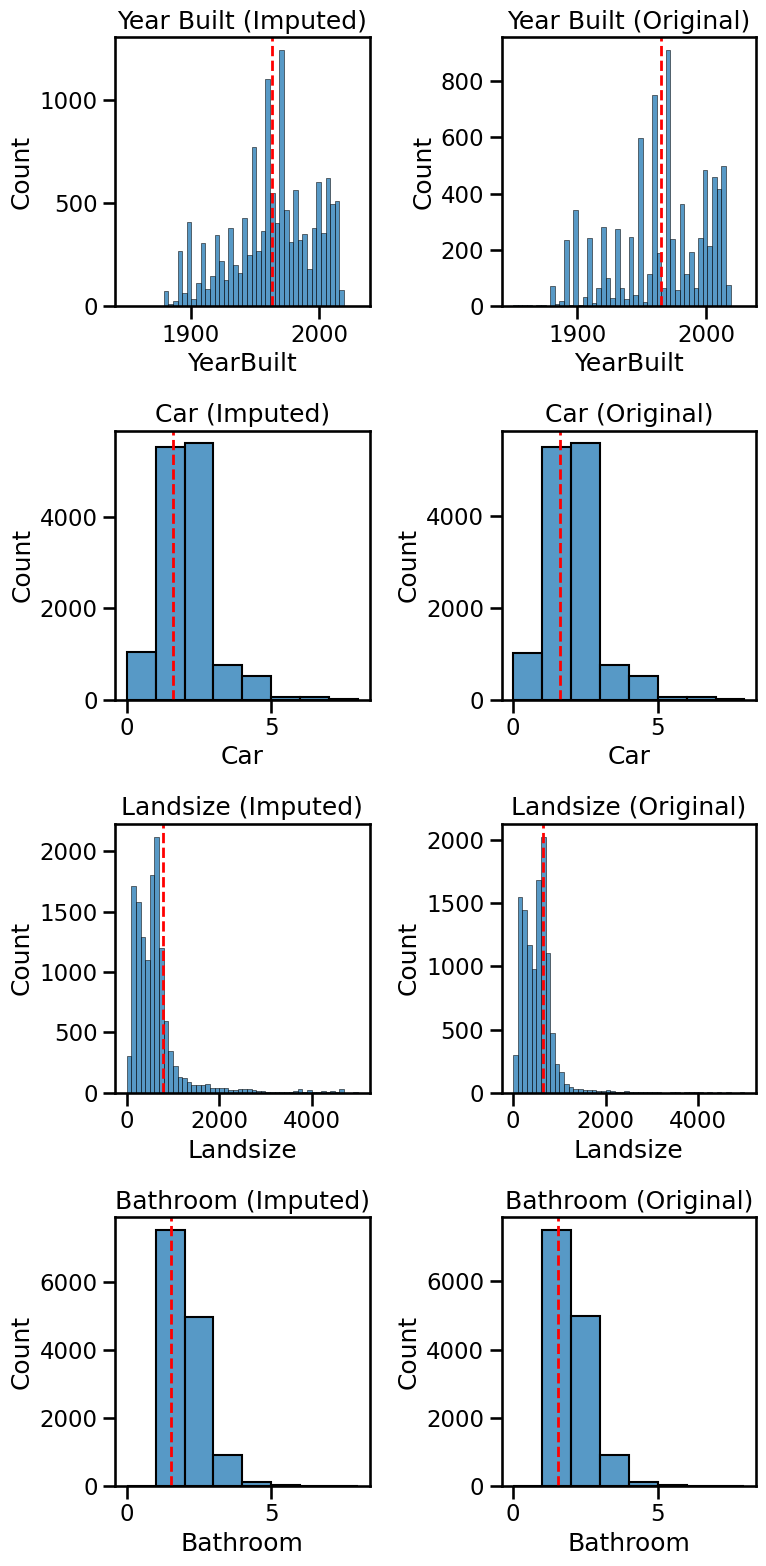

In [111]:
fig, axs = plt.subplots(4, 2, figsize=(8, 16)) # Increased rows to 4, adjusted figsize

# Histograma columna 1 (imputed 'YearBuilt')
sns.histplot(melb_imputed_df['YearBuilt'], bins=50, binrange=(1850, 2030), ax=axs[0, 0])
axs[0, 0].set_title("Year Built (Imputed)")
axs[0, 0].axvline(melb_imputed_df['YearBuilt'].mean(), color='red', linestyle='--', linewidth=2)

# Histograma columna 2 (original 'YearBuilt')
sns.histplot(melb_df_encoded['YearBuilt'], bins=50, binrange=(1850, 2030), ax=axs[0, 1])
axs[0, 1].set_title("Year Built (Original)")
axs[0, 1].axvline(melb_df_encoded['YearBuilt'].mean(), color='red', linestyle='--', linewidth=2)

# Histograma columna 1 (imputed 'Car')
sns.histplot(melb_imputed_df['Car'], bins=8, binrange=(0, 8), ax=axs[1, 0])
axs[1, 0].set_title("Car (Imputed)")
axs[1, 0].axvline(melb_imputed_df['Car'].mean(), color='red', linestyle='--', linewidth=2)

# Histograma columna 2 (original 'Car')
sns.histplot(melb_df_encoded['Car'], bins=8, binrange=(0, 8), ax=axs[1, 1])
axs[1, 1].set_title("Car (Original)")
axs[1, 1].axvline(melb_df_encoded['Car'].mean(), color='red', linestyle='--', linewidth=2)

# Histograma columna 1 (imputed 'Landsize')
sns.histplot(melb_imputed_df['Landsize'], bins=50, binrange=(0, 5000), ax=axs[2, 0])
axs[2, 0].set_title("Landsize (Imputed)")
axs[2, 0].axvline(melb_imputed_df['Landsize'].mean(), color='red', linestyle='--', linewidth=2)

# Histograma columna 2 (original 'Landsize')
sns.histplot(melb_df_encoded['Landsize'], bins=50, binrange=(0, 5000), ax=axs[2, 1])
axs[2, 1].set_title("Landsize (Original)")
axs[2, 1].axvline(melb_df_encoded['Landsize'].mean(), color='red', linestyle='--', linewidth=2)

# NEW: Histograma columna 1 (imputed 'Bathroom')
sns.histplot(melb_imputed_df['Bathroom'], bins=8, binrange=(0, 8), ax=axs[3, 0])
axs[3, 0].set_title("Bathroom (Imputed)")
axs[3, 0].axvline(melb_imputed_df['Bathroom'].mean(), color='red', linestyle='--', linewidth=2)

# NEW: Histograma columna 2 (original 'Bathroom')
sns.histplot(melb_df_encoded['Bathroom'], bins=8, binrange=(0, 8), ax=axs[3, 1])
axs[3, 1].set_title("Bathroom (Original)")
axs[3, 1].axvline(melb_df_encoded['Bathroom'].mean(), color='red', linestyle='--', linewidth=2)


plt.tight_layout()
plt.show()

Cualitativamente, los datos imputados conservan la forma general y la dispersión de las distribuciones originales, manteniéndose dentro de rangos físicamente razonables y sin introducir valores atípicos artificiales.

En las variables "Car" y "Bathroom" no se observan cambios significativos, lo cual era esperable dado que la cantidad de datos imputados en estos casos fue reducida. En cambio, para las variables "YearBuilt" y "Landsize", los valores imputados siguen la distribución característica de cada variable y se concentran en las regiones de mayor densidad de datos.

Particularmente, en "Landsize" se observa un leve desplazamiento de la media hacia valores mayores. Esto resulta consistente con el criterio de imputación utilizado, ya que los valores iguales a 0 fueron reemplazados imponiendo la condición de que la superficie mínima debía ser de $20m^{2}$.

## Ejercicio 3: Reducción de dimensionalidad.

Utilizando la matriz obtenida en el ejercicio anterior:
1. Aplique `PCA` para obtener $n$ componentes principales de la matriz, donde `n = min(20, X.shape[0])`. ¿Es necesario estandarizar o escalar los datos? Puede decidir si hacer PCA sobre todas las variables o bien seleccionar un subconjunto que crea pertinente.

2. Seleccione las proyecciones de los datos sobre las dos primeras componentes principales (las primeras dos columnas del resultado) para agregar como nuevas características al conjunto de datos.

In [112]:
melb_encoded_imputed_df = pd.DataFrame(melb_encoded_imputed, columns=melb_df_encoded.columns) #Se usa el dataframe con los datos estandarizados
print(melb_encoded_imputed_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 57 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rooms                                  13580 non-null  float64
 1   Price                                  13580 non-null  float64
 2   Distance                               13580 non-null  float64
 3   Postcode                               13580 non-null  float64
 4   Bathroom                               13580 non-null  float64
 5   Car                                    13580 non-null  float64
 6   Landsize                               13580 non-null  float64
 7   Lattitude                              13580 non-null  float64
 8   Longtitude                             13580 non-null  float64
 9   Propertycount                          13580 non-null  float64
 10  Type_h                                 13580 non-null  float64
 11  Ty

In [113]:
from sklearn.decomposition import PCA

X = melb_encoded_imputed[:,:20]

pca = PCA(n_components=min(20, melb_encoded_imputed.shape[1]))
X_pca = pca.fit_transform(X)

df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7","PC8", "PC9", "PC10","PC11", "PC12", "PC13", "PC14", "PC15", "PC16", "PC17","PC18", "PC19", "PC20"],
    #index=melb_encoded_imputed_df.index
)

pca.explained_variance_ratio_

array([1.65659231e-01, 1.16960789e-01, 8.16313775e-02, 7.84332198e-02,
       6.44342045e-02, 6.22144723e-02, 5.33709599e-02, 5.04109192e-02,
       4.87422472e-02, 4.38476148e-02, 3.95832873e-02, 3.81488656e-02,
       3.34508913e-02, 3.17024644e-02, 2.56952372e-02, 2.09376550e-02,
       1.80155839e-02, 1.54158198e-02, 1.13451601e-02, 3.52822487e-17])

In [114]:
df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20
0,-0.523528,-0.731937,-0.396664,-0.427437,-1.254338,-0.437975,0.557744,-0.059313,-1.006502,0.735506,0.031553,-0.078098,0.208386,0.734266,-0.273438,0.433995,0.438584,-0.378262,0.138156,1.221001e-16
1,-1.081631,-0.641551,-0.144533,-0.439179,-1.372064,-0.461754,0.696684,-0.051897,-1.384733,1.030710,0.142819,-0.184303,-0.216735,0.095226,-0.356791,0.054952,0.291385,-0.488854,-0.225891,-8.215894e-16
2,0.148467,-0.757295,-0.795880,-0.648198,-0.962778,-0.305275,0.557741,-0.032111,-1.018010,1.166025,0.220183,0.563964,-0.951143,-0.314150,-0.411984,-0.078305,0.221846,-0.454397,-0.218524,3.441447e-16
3,0.088919,-0.873121,-0.338525,-0.532796,-0.613991,-0.095416,0.313193,-0.048239,-0.556177,0.709837,-0.169645,0.564427,-0.377056,-0.000878,-0.372730,-0.219075,0.293176,-0.795769,-0.867028,-7.660783e-16
4,0.798598,-1.036940,-0.513395,-0.442614,-0.805130,-0.325931,0.314856,-0.036918,-0.442779,0.385956,-0.277480,0.275369,0.266259,0.972135,-0.238655,0.094302,0.502191,1.004304,-0.651665,-1.099145e-15


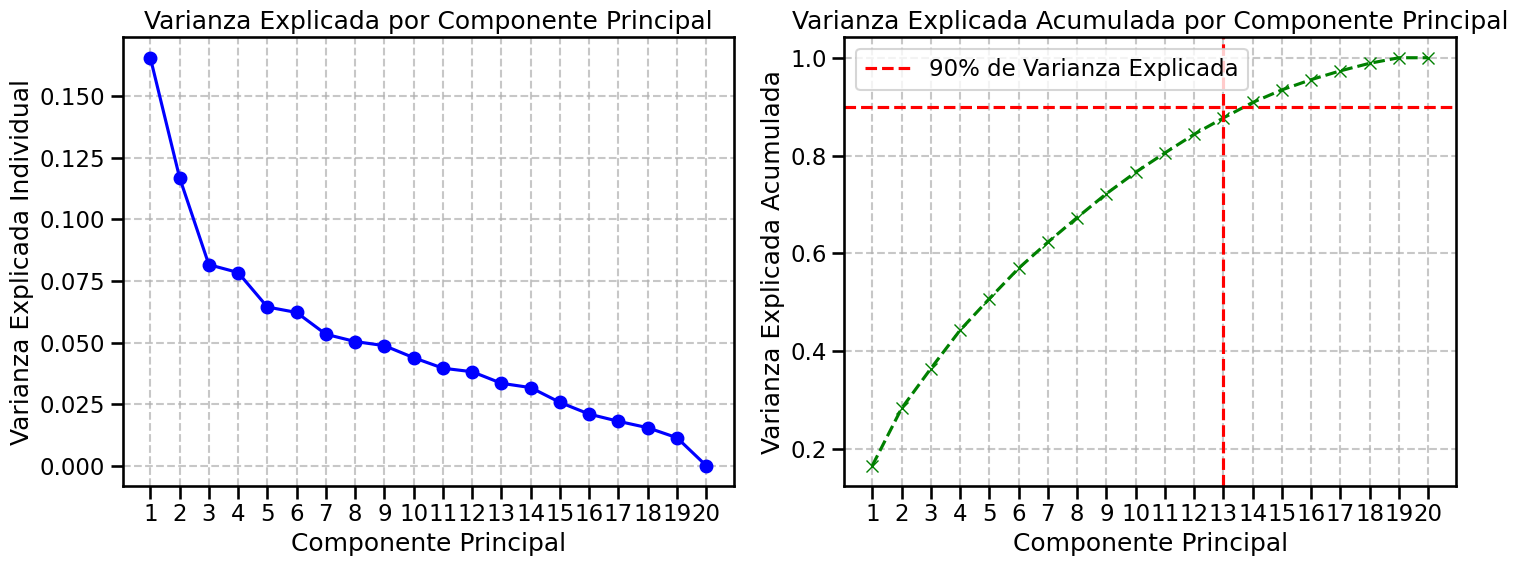

In [115]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Varianza Explicada Individual
axs[0].plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker='o', linestyle='-', color='blue')
axs[0].set_xlabel('Componente Principal')
axs[0].set_ylabel('Varianza Explicada Individual')
axs[0].set_title('Varianza Explicada por Componente Principal')
axs[0].set_xticks(range(1, len(pca.explained_variance_ratio_) + 1))
axs[0].grid(axis='both', linestyle='--', alpha=0.7)

# Panel 2: Varianza Explicada Acumulada
axs[1].plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker='x', linestyle='--', color='green')
axs[1].set_xlabel('Componente Principal')
axs[1].set_ylabel('Varianza Explicada Acumulada')
axs[1].set_title('Varianza Explicada Acumulada por Componente Principal')
axs[1].set_xticks(range(1, len(pca.explained_variance_ratio_) + 1))
axs[1].grid(axis='both', linestyle='--', alpha=0.7)
axs[1].axhline(y=0.9, color='red', linestyle='--', label='90% de Varianza Explicada')
axs[1].axvline(x=13, color='red', linestyle='--')
axs[1].legend()

plt.tight_layout()
plt.show()

Basta con 12 componentes principales para explicar el 90% de la varianza.

## Ejercicio 2.2

In [116]:
melb_final_df = pd.concat([melb_imputed_df, df_pca[['PC1', 'PC2']]], axis=1) #Se concatena el DF desescalado con las PC
display(melb_final_df.head())

,Rooms,Price,Distance,Postcode,Bathroom,Car,Landsize,Lattitude,Longtitude,Propertycount,...,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria,YearBuilt,BuildingArea,PC1,PC2
0,2.0,1480000.0,2.5,3067.0,1.0,1.0,202.0,-37.7996,144.9984,4019.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1914.0,96.4,-0.523528,-0.731937
1,2.0,1035000.0,2.5,3067.0,1.0,0.0,156.0,-37.8079,144.9934,4019.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1900.0,79.0,-1.081631,-0.641551
2,3.0,1465000.0,2.5,3067.0,2.0,0.0,134.0,-37.8093,144.9944,4019.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1900.0,150.0,0.148467,-0.757295
3,3.0,850000.0,2.5,3067.0,2.0,1.0,94.0,-37.7969,144.9969,4019.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1932.4,125.0,0.088919,-0.873121
4,4.0,1600000.0,2.5,3067.0,1.0,2.0,120.0,-37.8072,144.9941,4019.0,...,1.0,0.0,0.0,0.0,0.0,0.0,2014.0,142.0,0.798598,-1.036940


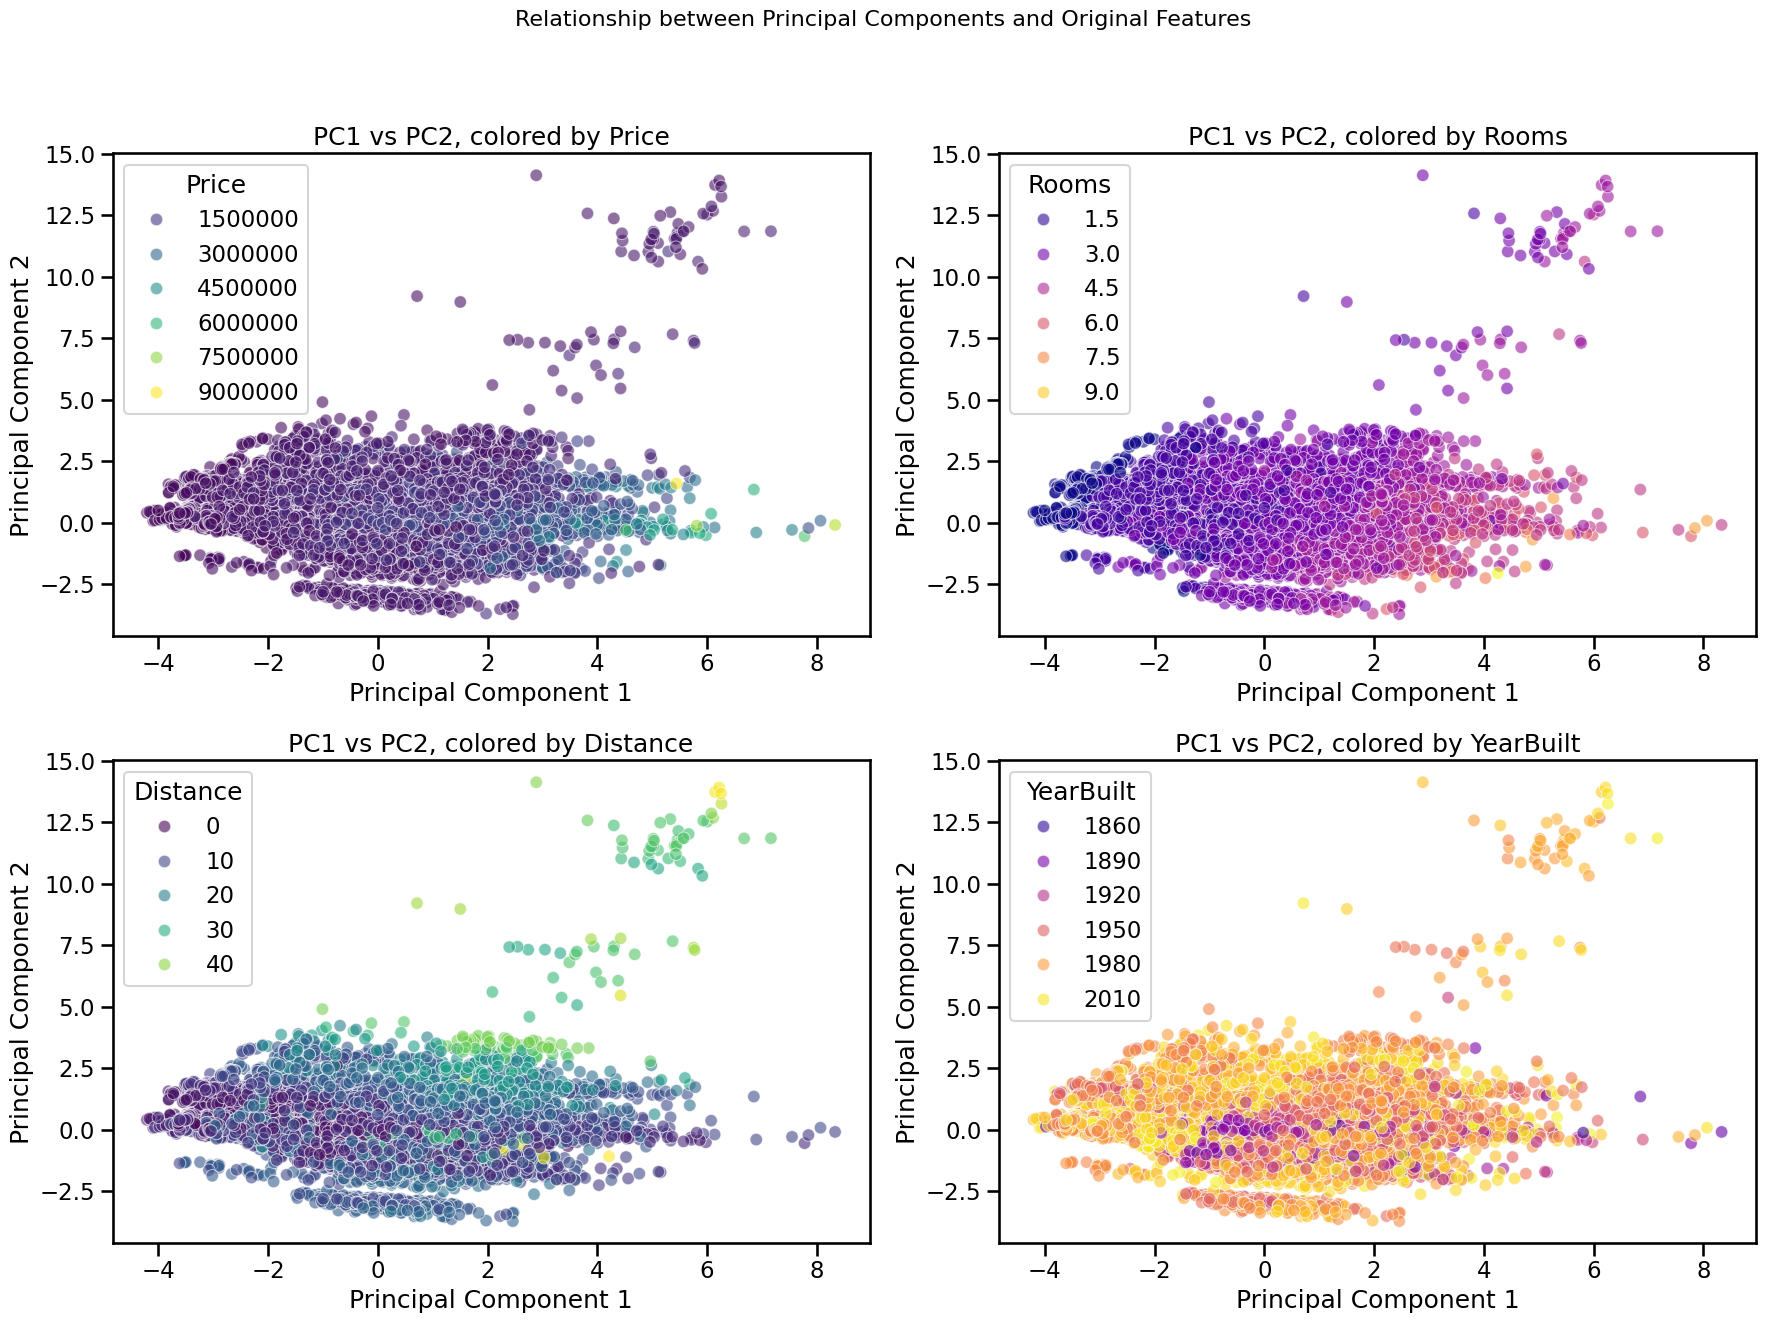

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Relationship between Principal Components and Original Features', fontsize=16)

# Panel 1: PC1 vs PC2, colored by Price
sns.scatterplot(data=melb_final_df, x='PC1', y='PC2', hue='Price', palette='viridis', alpha=0.6, ax=axes[0, 0])
axes[0, 0].set_title('PC1 vs PC2, colored by Price')
axes[0, 0].set_xlabel('Principal Component 1')
axes[0, 0].set_ylabel('Principal Component 2')

# Panel 2: PC1 vs PC2, colored by Rooms
sns.scatterplot(data=melb_final_df, x='PC1', y='PC2', hue='Rooms', palette='plasma', alpha=0.6, ax=axes[0, 1])
axes[0, 1].set_title('PC1 vs PC2, colored by Rooms')
axes[0, 1].set_xlabel('Principal Component 1')
axes[0, 1].set_ylabel('Principal Component 2')

# Panel 3: PC1 vs PC2, colored by Distance
sns.scatterplot(data=melb_final_df, x='PC1', y='PC2', hue='Distance', palette='viridis', alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title('PC1 vs PC2, colored by Distance')
axes[1, 0].set_xlabel('Principal Component 1')
axes[1, 0].set_ylabel('Principal Component 2')

# Panel 4: PC1 vs PC2, colored by YearBuilt
sns.scatterplot(data=melb_final_df, x='PC1', y='PC2', hue='YearBuilt', palette='plasma', alpha=0.6, ax=axes[1, 1])
axes[1, 1].set_title('PC1 vs PC2, colored by YearBuilt')
axes[1, 1].set_xlabel('Principal Component 1')
axes[1, 1].set_ylabel('Principal Component 2')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
plt.show()

Cuando proyectamos los datos sobre las primeras dos componentes principales, observamos que la mayor dispersión ocurre a lo largo de la primera componente principal (PC1). Esto indica que PC1 concentra la mayor parte de la variabilidad presente en el conjunto de datos.

Al colorear los puntos según distintas variables originales, se identifican patrones interesantes. En particular, para las variables "Price" y "Rooms", el gradiente de colores cambia principalmente a lo largo de PC1, especialmente hacia valores positivos de esta componente. Esto sugiere que ambas variables están fuertemente asociadas con la variabilidad capturada por PC1. En otras palabras, propiedades con mayores precios y mayor cantidad de habitaciones tienden a ubicarse hacia valores altos de la primera componente principal.

En el caso de "Distance", el cambio en el mapa de colores se observa principalmente en dirección de PC2, aunque también presenta cierta dependencia con PC1. Esto indica que la distancia contribuye de manera importante a la segunda componente principal y, en menor medida, también a la primera.

Por otro lado, para la variable "YearBuilt" no se observa una tendencia global clara asociada a ninguna de las dos componentes principales. Sin embargo, aparecen agrupamientos de colores en ciertas regiones del espacio PCA, lo que podría indicar relaciones más complejas o no lineales con otras variables del conjunto de datos.

En conclusión, el análisis de componentes principales permite identificar qué variables contribuyen más significativamente a las direcciones de máxima variabilidad del conjunto de datos. En este caso, la primera componente parece estar principalmente relacionada con características asociadas al tamaño y valor de las propiedades, mientras que la segunda componente captura variaciones vinculadas con la ubicación, particularmente la distancia.

## Ejercicio 4: Composición del resultado

Transformar nuevamente el conjunto de datos procesado en un `pandas.DataFrame` y guardarlo en un archivo.

Para eso, será necesario recordar el nombre original de cada columna de la matriz, en el orden correcto. Tener en cuenta:
1. El método `OneHotEncoder.get_feature_names` o el atributo `OneHotEncoder.categories_` permiten obtener una lista con los valores de la categoría que le corresponde a cada índice de la matriz.
2. Ninguno de los métodos aplicados intercambia de lugar las columnas o las filas de la matriz.

In [118]:
from sklearn.impute import SimpleImputer

# Identificamos las columnas categóricas encodeadas de la matriz final:
ohe_columns_in_final_df = [col for col in melb_final_df.columns if col.startswith(('Type_', 'CouncilArea_', 'Regionname_'))]

# Creamos un data frame sólo numérico
numerical_and_pca_cols = [col for col in melb_final_df.columns if col not in ohe_columns_in_final_df]
melb_final_numeric_pca = melb_final_df[numerical_and_pca_cols].copy()

# Copiamos los valores categóricos originales
original_categorical_data = melb_df[['Type', 'CouncilArea', 'Regionname']].copy()

# 3. Imputamos 'CouncilArea' con la moda
imputer_mode = SimpleImputer(strategy='most_frequent')
original_categorical_data['CouncilArea'] = imputer_mode.fit_transform(original_categorical_data[['CouncilArea']]).ravel()

# Finalmente, concatenamos las matrices, y guardamos todo en un .CSV
melb_final_df = pd.concat([melb_final_numeric_pca, original_categorical_data], axis=1)

melb_final_df.to_csv('melb_processed.csv', index=False)
print('Processed data saved to melb_processed.csv')

Processed data saved to melb_processed.csv


El DataFrame final contiene 14 variables numéricas, siendo dos de ellas componentes principales de PCA, y 3 variables categóricas. La variable CouncilArea, finalmente, fue imputada con un imputador simple, agregando el valor de su moda a sus datos faltantes.

In [119]:
melb_final_df.info() #observamos la forma final del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Rooms          13580 non-null  float64
 1   Price          13580 non-null  float64
 2   Distance       13580 non-null  float64
 3   Postcode       13580 non-null  float64
 4   Bathroom       13580 non-null  float64
 5   Car            13580 non-null  float64
 6   Landsize       13580 non-null  float64
 7   Lattitude      13580 non-null  float64
 8   Longtitude     13580 non-null  float64
 9   Propertycount  13580 non-null  float64
 10  YearBuilt      13580 non-null  float64
 11  BuildingArea   13580 non-null  float64
 12  PC1            13580 non-null  float64
 13  PC2            13580 non-null  float64
 14  Type           13580 non-null  object 
 15  CouncilArea    13580 non-null  object 
 16  Regionname     13580 non-null  object 
dtypes: float64(14), object(3)
memory usage: 1.8+ MB


## Ejercicio 5: Documentación

En un documento `.pdf` o `.md` realizar un reporte de las operaciones que realizaron para obtener el conjunto de datos final. Se debe incluir:
  1. Criterios de exclusión (o inclusión) de filas o columnas
  2. Interpretación de las columnas presentes
  2. Todas las transofrmaciones realizadas

Se adjunta el documento pertinente en conjunto con la entrega de este código.
```
